In [123]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [124]:
filename = "G:/neural network/loan_approval/loan_approval_dataset.csv"
df = pd.read_csv(filename)
df.head(1)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved


In [125]:
df.shape

(4269, 13)

In [126]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [127]:
df_small = df.sample(2000,random_state=42)
approved = df_small[df_small[' loan_status'] == ' Approved']
rejected = df_small[df_small[' loan_status'] == ' Rejected']

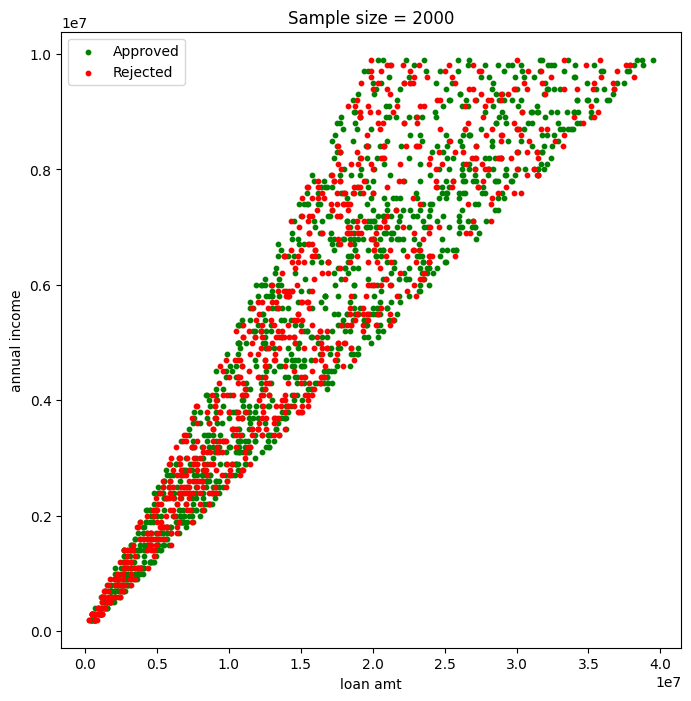

In [128]:
# income_annum vs loan_amount on loan_status
plt.figure(figsize=(8,8))
plt.scatter(approved[' loan_amount'], approved[' income_annum'],s=10, color='green', label='Approved')
plt.scatter(rejected[' loan_amount'], rejected[' income_annum'],s=10, color='red', label='Rejected')
plt.xlabel("loan amt")
plt.ylabel("annual income")
plt.title("Sample size = 2000")
plt.legend()
plt.show()

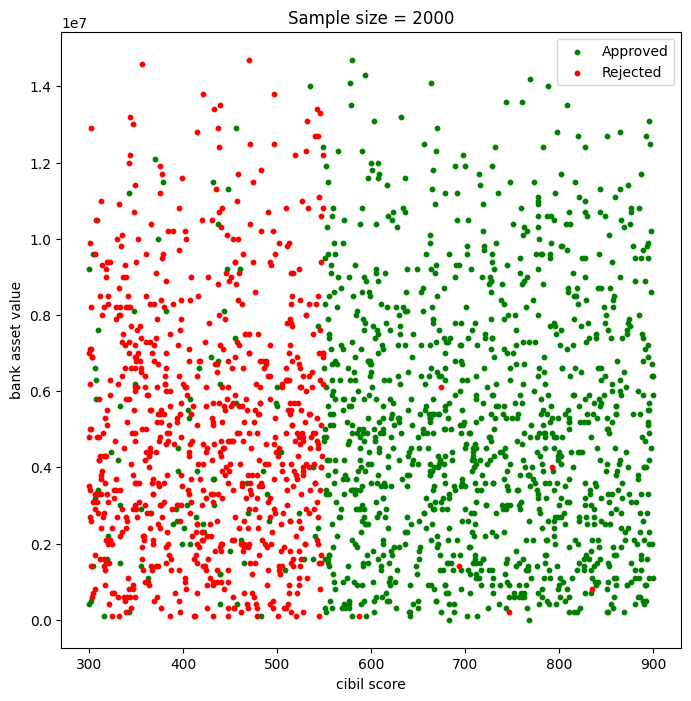

In [129]:
# cibil score vs bank_asset_value and loan amount
plt.figure(figsize=(8,8))
plt.scatter(approved[' cibil_score'], approved[' bank_asset_value'],s=10, color='green', label='Approved')
plt.scatter(rejected[' cibil_score'], rejected[' bank_asset_value'],s=10, color='red', label='Rejected')
plt.xlabel("cibil score")
plt.ylabel("bank asset value")
plt.title("Sample size = 2000")
plt.legend()
plt.show()

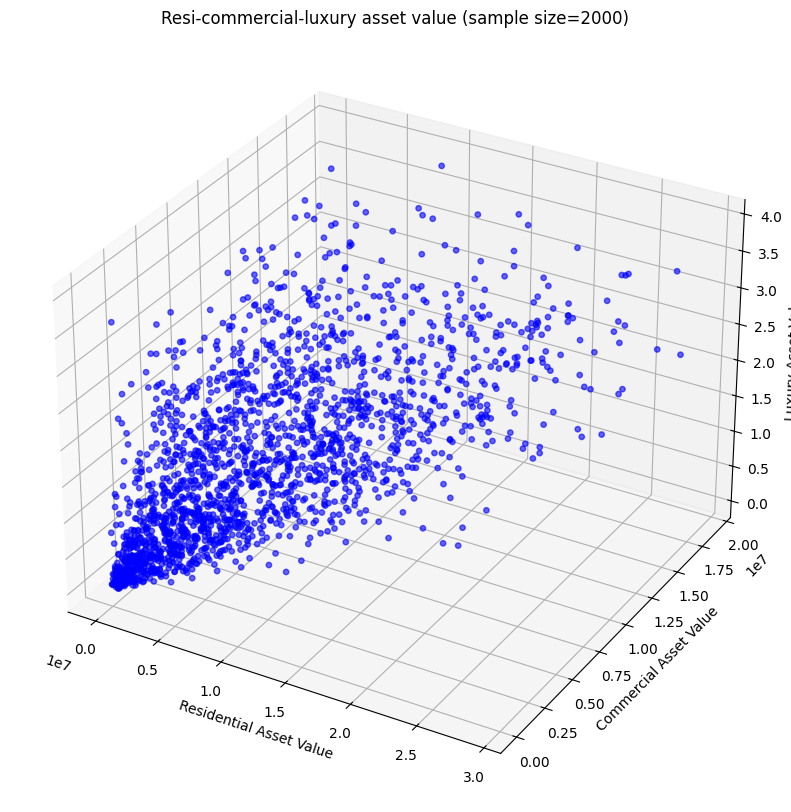

In [130]:
# residential_asset value vs commercial_asset_value vs luxury_asset_value
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df_small[' residential_assets_value'],
    df_small[' commercial_assets_value'],
    df_small[' luxury_assets_value'],
    s=15,
    alpha=0.6,
    c='blue'
)
ax.set_xlabel('Residential Asset Value')
ax.set_ylabel('Commercial Asset Value')
ax.set_zlabel('Luxury Asset Value')
ax.set_title('Resi-commercial-luxury asset value (sample size=2000)')
plt.show()

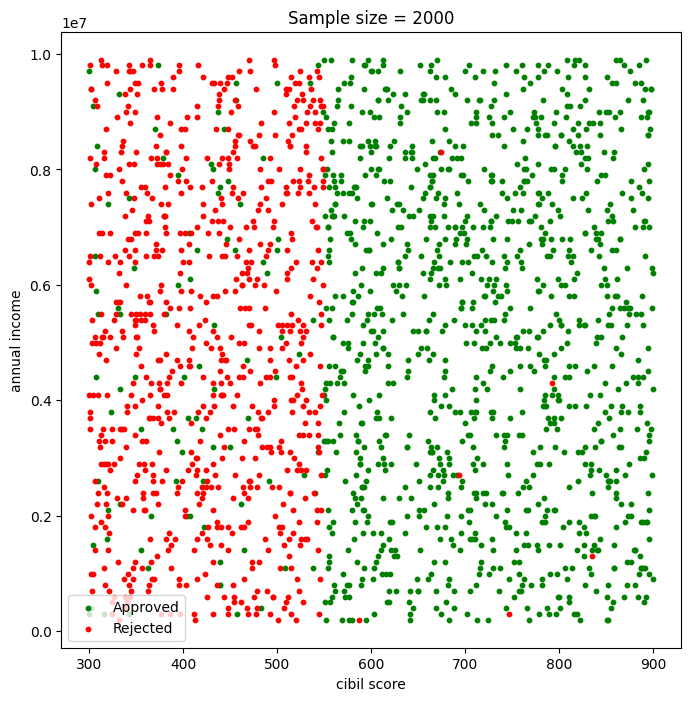

In [131]:
# annual income vs cibil score and loan status
plt.figure(figsize=(8,8))
plt.scatter(approved[' cibil_score'], approved[' income_annum'],s=10, color='green', label='Approved')
plt.scatter(rejected[' cibil_score'], rejected[' income_annum'],s=10, color='red', label='Rejected')
plt.xlabel("cibil score")
plt.ylabel("annual income")
plt.title("Sample size = 2000")
plt.legend()
plt.show()

In [132]:
df_sort1 = df[[' self_employed', ' income_annum', ' loan_amount', ' cibil_score', ' loan_status']].copy()
df_sort1.head()

,self_employed,income_annum,loan_amount,cibil_score,loan_status
0,No,9600000,29900000,778,Approved
1,Yes,4100000,12200000,417,Rejected
2,No,9100000,29700000,506,Rejected
3,No,8200000,30700000,467,Rejected
4,Yes,9800000,24200000,382,Rejected


In [133]:
df_sort1 = pd.get_dummies(
    df_sort1,
    columns=[' self_employed', ' loan_status'],
    dtype=int
)
df_sort1.head()

,income_annum,loan_amount,cibil_score,self_employed_ No,self_employed_ Yes,loan_status_ Approved,loan_status_ Rejected
0,9600000,29900000,778,1,0,1,0
1,4100000,12200000,417,0,1,0,1
2,9100000,29700000,506,1,0,0,1
3,8200000,30700000,467,1,0,0,1
4,9800000,24200000,382,0,1,0,1


In [134]:
df_sort1.columns

Index([' income_annum', ' loan_amount', ' cibil_score', ' self_employed_ No',
       ' self_employed_ Yes', ' loan_status_ Approved',
       ' loan_status_ Rejected'],
      dtype='object')

In [135]:
X = df_sort1.drop(columns=[
    ' loan_status_ Approved',
    ' loan_status_ Rejected'
])

Y = df_sort1[' loan_status_ Approved']

np.random.seed(42)
indices = np.random.permutation(len(df_sort1))

split = int(0.8 * len(df_sort1))

train_indices = indices[:split]
test_indices = indices[split:]

X_train = X.iloc[train_indices].to_numpy(dtype=float)
X_test = X.iloc[test_indices].to_numpy(dtype=float)

y_train = Y.iloc[train_indices].to_numpy().reshape(-1, 1)
y_test = Y.iloc[test_indices].to_numpy().reshape(-1, 1)


In [136]:
X_train[0][0]

np.float64(5400000.0)

In [137]:
# standardization of the features
# we have 5 features
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [138]:
print("X_train mean:", np.mean(X_train, axis=0))
print("X_train std:", np.std(X_train, axis=0))

print("X_train max:", np.max(np.abs(X_train)))

X_train mean: [ 1.42524678e-16  8.32260891e-17 -2.47597615e-16  4.16130446e-17
 -2.08065223e-18]
X_train std: [1. 1. 1. 1. 1.]
X_train max: 2.6939296701267152


In [139]:
#initializing weights and bias
weights = np.zeros((X_train.shape[1],1))
bias = 0.0

In [140]:
#sigmoid function
def sigmoid(z):
    return 1/(1+np.exp(-z))

print(sigmoid(5))

0.9933071490757153


In [141]:
#forward
def forward(X, weights, bias):
    z = np.dot(X,weights) + bias
    y_pred = sigmoid(z)
    return y_pred

In [142]:
def loss_function(y,y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred,epsilon,1-epsilon)

    loss = -np.mean(
        y*np.log(y_pred) + (1-y)*np.log(1-y_pred)
    )
    return loss

In [143]:
y_pred = forward(X_train, weights, bias)

loss = loss_function(y_train, y_pred)

print("Initial Loss:", loss)

Initial Loss: 0.6931471805599454


In [144]:
def gradient(X,y,y_pred):
    m = X.shape[0]
    error = y_pred - y
    dw = np.dot(X.T,error)/m
    db = np.sum(error)/m
    return dw,db

In [145]:
dw, db = gradient(X_train, y_train, y_pred)

print("Weight gradients:")
print(dw)

print("Bias gradient:")
print(db)

Weight gradients:
[[ 0.00431303]
 [-0.0111872 ]
 [-0.37107872]
 [-0.00260585]
 [ 0.00260585]]
Bias gradient:
-0.12020497803806734


In [146]:
def gradient_descent(weights, bias, dw, db, learning_rate):
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db
    return weights, bias

In [147]:
learning_rate = 0.005
epochs = 5000
loss_history = []
epochs_list = [n for n in range(1,5001)]
for epoch in range(epochs):
    y_pred = forward(X_train, weights, bias)
    loss = loss_function(y_train, y_pred)
    loss_history.append(loss)
    dw, db = gradient(X_train, y_train, y_pred)
    weights, bias = gradient_descent(
        weights, bias, dw, db, learning_rate
    )
    if epoch % 500 == 0:
        print(f"Epoch: {epoch}, Loss: {loss:.6f}")

Epoch: 0, Loss: 0.693147
Epoch: 500, Loss: 0.470824
Epoch: 1000, Loss: 0.389427
Epoch: 1500, Loss: 0.349869
Epoch: 2000, Loss: 0.326919
Epoch: 2500, Loss: 0.312065
Epoch: 3000, Loss: 0.301731
Epoch: 3500, Loss: 0.294166
Epoch: 4000, Loss: 0.288416
Epoch: 4500, Loss: 0.283917


In [150]:
np.savez(
    "loan_model.npz",
    weights=weights,
    bias=bias,
    means=mean,
    stds=std
)

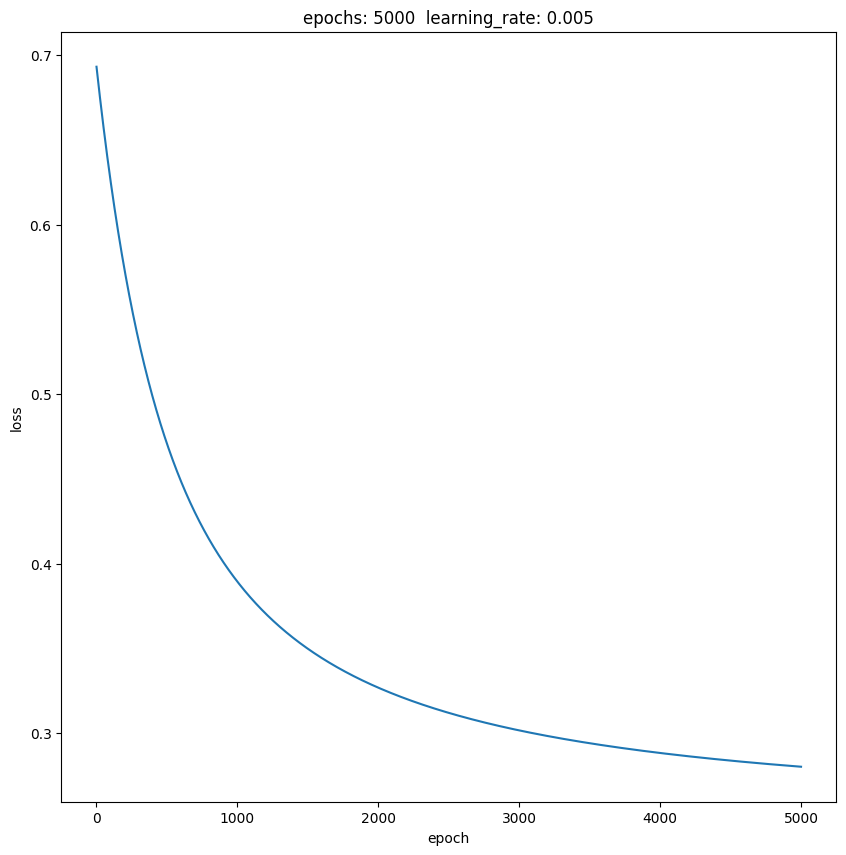

In [148]:
plt.figure(figsize=(10,10))
plt.plot(epochs_list,loss_history)
plt.title("epochs: 5000  learning_rate: 0.005")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [152]:
model = np.load("loan_model.npz")
weights = model["weights"]
bias = model["bias"]
mean = model["means"]
std = model["stds"]

In [153]:
def predict_loan(data, weights, bias, means, stds):
    data = np.array(data, dtype=float)
    data = (data - means) / stds
    probability = forward(data, weights, bias)
    prediction = (probability >= 0.5).astype(int)
    return probability, prediction

In [155]:
new_data = [[5000000, 1500000, 750, 0, 1]]

prob, pred = predict_loan(
    new_data,
    weights,
    bias,
    mean,
    std
)

print("Approval probability:", prob[0, 0])
print("Prediction:", "Approved" if pred[0, 0] == 1 else "Rejected")

Approval probability: 0.9372677297370238
Prediction: Approved


In [156]:
y_test_prob = forward(X_test, weights, bias)

y_test_pred = (y_test_prob >= 0.5).astype(int)

In [157]:
accuracy = np.mean(y_test_pred == y_test)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 93.09%


In [158]:
comparison = np.concatenate(
    (y_test, y_test_pred, y_test_prob),
    axis=1
)

print(comparison[:20])

[[1.         1.         0.9834988 ]
 [1.         1.         0.98995722]
 [1.         1.         0.9808531 ]
 [1.         0.         0.2048974 ]
 [0.         0.         0.08497923]
 [1.         1.         0.84272977]
 [1.         1.         0.94960006]
 [1.         1.         0.98966365]
 [1.         1.         0.98718428]
 [0.         0.         0.05151062]
 [0.         0.         0.47822144]
 [0.         0.         0.0982744 ]
 [0.         0.         0.08001702]
 [1.         1.         0.83407786]
 [0.         0.         0.03696684]
 [1.         1.         0.9024932 ]
 [0.         0.         0.32622498]
 [1.         1.         0.9920265 ]
 [1.         1.         0.89997456]
 [1.         1.         0.67201595]]


In [159]:
TP = np.sum((y_test == 1) & (y_test_pred == 1))
TN = np.sum((y_test == 0) & (y_test_pred == 0))
FP = np.sum((y_test == 0) & (y_test_pred == 1))
FN = np.sum((y_test == 1) & (y_test_pred == 0))

confusion_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

print(confusion_matrix)

[[288  28]
 [ 31 507]]
